# Linear case: Ornstein--Uhlenbeck with Kalman, UKF, and particle filter

This notebook studies the **linear-Gaussian** case, where the optimal filter is known in closed form. It runs three filters on a scalar Ornstein--Uhlenbeck (OU) model:

- the **Kalman filter**, which is exact here;
- the **unscented Kalman filter** (UKF), used as a sanity check: on a linear model it must reproduce the Kalman filter;
- the **bootstrap particle filter** (PF), which approximates the same law by samples.

The linear case is the reference point. The Kalman filter gives the exact answer, so we can check that the UKF matches it and that the particle filter converges to it as the number of particles grows. Run top to bottom (*Kernel -> Restart & Run All*); all outputs go to `figures/`.

## The Ornstein--Uhlenbeck model

The hidden state is a scalar OU process,

$$dX_t = -\theta\, X_t \, dt + \sigma \, dW_t,$$

observed at times $t_k = k\,\Delta t$ through a linear noisy sensor,

$$Y_k = X_{t_k} + \varepsilon_k, \qquad \varepsilon_k \sim \mathcal{N}(0, R).$$

Parameters: $\theta = 0.5$, $\sigma = 1$, $\Delta t = 1$, $R = 0.5$, horizon $50$ steps. The initial law is the stationary law $X_0 \sim \mathcal{N}(0,\, \sigma^2/2\theta)$.

## Discretization

Over one step of length $\Delta t$ the OU process integrates exactly to a linear-Gaussian transition,

$$X_k = A\,X_{k-1} + w_k, \qquad w_k \sim \mathcal{N}(0, Q),$$

with

$$A = e^{-\theta \Delta t}, \qquad Q = \frac{\sigma^2}{2\theta}\left(1 - e^{-2\theta \Delta t}\right).$$

Unlike the Kitagawa map, this transition is the exact integral of the SDE, so the discrete model fed to the filters is the sampled OU process itself. The three filters run on $(A, Q, H = 1, R)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import logsumexp
import time, csv

# --- OU model and experiment parameters ---
THETA   = 0.5      # mean-reversion rate
SIGMA   = 1.0      # diffusion coefficient
DT      = 1.0      # sampling interval
R_OBS   = 0.5      # observation-noise variance
N_STEPS = 50       # horizon (number of steps)
X0_MEAN = 0.0
X0_VAR  = SIGMA**2 / (2*THETA)          # stationary variance = initial variance
BASE_SEED = 20260716
M_SEEDS   = 50     # realizations for the time-averaged MSE

# Exact discretization of the OU process over one step of length DT:
#   X_k = A X_{k-1} + w_k,  w_k ~ N(0, Q)
A = np.exp(-THETA*DT)                              # transition coefficient
Q = SIGMA**2 / (2*THETA) * (1 - np.exp(-2*THETA*DT))  # process-noise variance
H = 1.0                                            # linear observation

COLORS = {"truth": "black", "kalman": "tab:blue", "ukf": "tab:green", "pf": "tab:red"}
FIGURE_DIR = Path("figures"); FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIGURE_DIR/name, bbox_inches="tight"); plt.show()
    print("saved", FIGURE_DIR/name)

# One realization of the sampled OU model: returns (rng, x_true, y)
def simulate(seed):
    rng = np.random.default_rng(seed)
    x = np.empty(N_STEPS+1); y = np.full(N_STEPS+1, np.nan)
    x[0] = rng.normal(X0_MEAN, np.sqrt(X0_VAR))
    for k in range(1, N_STEPS+1):
        x[k] = A*x[k-1] + rng.normal(0, np.sqrt(Q))
        y[k] = H*x[k]  + rng.normal(0, np.sqrt(R_OBS))
    return rng, x, y

print("A = %.4f, Q = %.4f, stationary var = %.4f" % (A, Q, X0_VAR))

A = 0.6065, Q = 0.6321, stationary var = 1.0000


## Kalman filter

The Kalman filter is exact for this model. It keeps a mean and a variance and updates them by the predict--correct recursion.

In [2]:
# Exact linear-Gaussian filter. Returns mean and variance tracks.
def run_kalman(y):
    m = np.empty(N_STEPS+1); P = np.empty(N_STEPS+1)
    m[0], P[0] = X0_MEAN, X0_VAR
    for k in range(1, N_STEPS+1):
        mp = A*m[k-1]; Pp = A*A*P[k-1] + Q            # predict
        S = H*H*Pp + R_OBS; K = Pp*H/S                # innovation variance, gain
        m[k] = mp + K*(y[k] - H*mp); P[k] = (1 - K*H)*Pp   # correct
    return m, P

## Unscented Kalman filter

The UKF runs the same recursion through sigma points, with the linear maps $f(x) = A x$ and $h(x) = x$. Because the unscented transform is exact for affine maps, the UKF must reproduce the Kalman mean and variance up to rounding. We check this below.

In [3]:
# Unscented filter on the linear model. Must reproduce the Kalman filter.
def run_ukf(y):
    alpha, beta, kappa = 1.0, 2.0, 0.0
    lam = alpha**2*(1+kappa) - 1                      # = 0 for these values
    Wm = np.array([lam/(1+lam), 1/(2*(1+lam)), 1/(2*(1+lam))])
    Wc = Wm.copy(); Wc[0] += 1 - alpha**2 + beta
    def sp(mm, PP):
        d = np.sqrt(max((1+lam)*PP, 1e-14)); return np.array([mm, mm+d, mm-d])
    f = lambda x: A*x
    h = lambda x: H*x
    m = np.empty(N_STEPS+1); P = np.empty(N_STEPS+1)
    m[0], P[0] = X0_MEAN, X0_VAR
    for k in range(1, N_STEPS+1):
        xp = f(sp(m[k-1], P[k-1])); mp = Wm@xp; Pp = Wc@((xp-mp)**2) + Q
        zp = h(sp(mp, Pp)); zm = Wm@zp; S = Wc@((zp-zm)**2) + R_OBS
        C = Wc@((sp(mp, Pp)-mp)*(zp-zm)); K = C/S
        m[k] = mp + K*(y[k]-zm); P[k] = max(Pp - K*K*S, 1e-12)
    return m, P

## Particle filter

The bootstrap particle filter represents the law by weighted samples. It propagates each particle through the dynamics, weights it by the likelihood of the observation, and resamples. Its estimate is random and approaches the Kalman answer as the number of particles grows.

In [4]:
# Bootstrap particle filter with systematic resampling. Returns the mean track.
def run_pf(rng, y, n):
    def systematic_resample(w, rng):
        u = (rng.random() + np.arange(len(w)))/len(w)
        return np.searchsorted(np.cumsum(w), u)
    part = rng.normal(X0_MEAN, np.sqrt(X0_VAR), n)
    m = np.empty(N_STEPS+1); m[0] = part.mean()
    for k in range(1, N_STEPS+1):
        part = A*part + rng.normal(0, np.sqrt(Q), n)      # propagate
        logw = -0.5*(y[k]-H*part)**2/R_OBS               # log-likelihood
        w = np.exp(logw - logsumexp(logw))               # normalized weights
        m[k] = w@part                                    # posterior mean
        part = part[systematic_resample(w, rng)]         # resample
    return m

## Comparison and metrics

We run the three filters on one realization and compare their estimates against the true state. The table reports the average mean squared error over the horizon and the compute time of each filter. The UKF--Kalman gap is printed to confirm the two coincide.

max |UKF mean - Kalman mean| = 4.44e-16


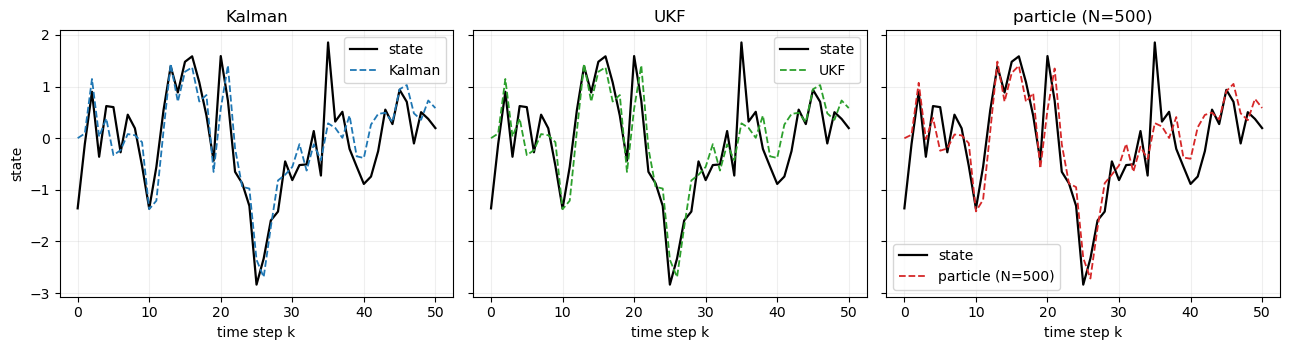

saved figures/ou_estimates.pdf


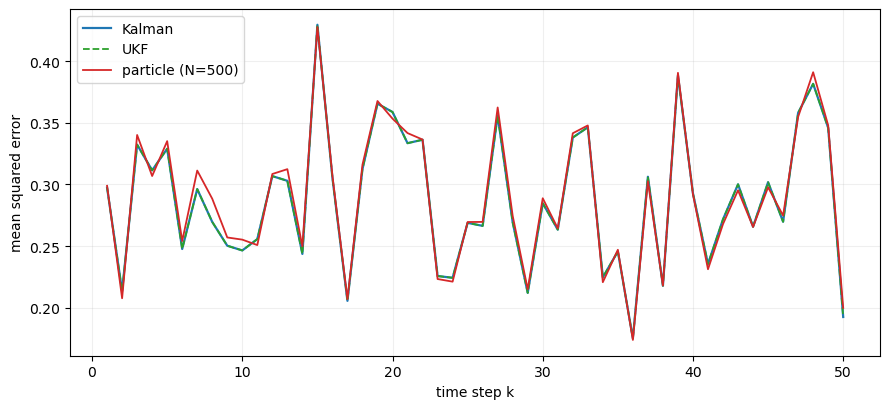

saved figures/ou_mse_time.pdf
avg MSE  Kalman 0.2876 | UKF 0.2876 | PF 0.2897
time [s] Kalman 0.00013 | UKF 0.00181 | PF 0.02045
saved figures/ou_metrics.csv


In [5]:
# Representative realization
rng0, x0, y0 = simulate(BASE_SEED)
t = np.arange(N_STEPS+1)
N_PF = 500

def timed(fn):
    t0 = time.perf_counter(); out = fn(); return out, time.perf_counter()-t0

(km, kP), t_kal = timed(lambda: run_kalman(y0))
(um, uP), t_ukf = timed(lambda: run_ukf(y0))
pm, t_pf = timed(lambda: run_pf(np.random.default_rng(BASE_SEED+1), y0, N_PF))

# UKF vs Kalman: should match to machine precision
ukf_kalman_gap = np.max(np.abs(um - km))
print("max |UKF mean - Kalman mean| = %.2e" % ukf_kalman_gap)

# (1) three-panel: true state vs estimate
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
panels = [("Kalman", km, "kalman"), ("UKF", um, "ukf"), ("particle (N=%d)" % N_PF, pm, "pf")]
for a, (name, est, col) in zip(ax, panels):
    a.plot(t, x0, color=COLORS["truth"], lw=1.6, label="state")
    a.plot(t, est, color=COLORS[col], lw=1.3, ls="--", label=name)
    a.set_title(name); a.set_xlabel("time step k"); a.grid(alpha=.2); a.legend()
ax[0].set_ylabel("state")
savefig("ou_estimates.pdf")

# (2) time-averaged MSE over M_SEEDS realizations
se_k = np.zeros(N_STEPS+1); se_u = np.zeros(N_STEPS+1); se_p = np.zeros(N_STEPS+1)
for s in range(BASE_SEED, BASE_SEED+M_SEEDS):
    rng_s, x_s, y_s = simulate(s)
    mk, _ = run_kalman(y_s); mu, _ = run_ukf(y_s)
    mp_s = run_pf(np.random.default_rng(s+1000000), y_s, N_PF)
    se_k += (mk-x_s)**2; se_u += (mu-x_s)**2; se_p += (mp_s-x_s)**2
se_k /= M_SEEDS; se_u /= M_SEEDS; se_p /= M_SEEDS

plt.figure(figsize=(9, 4.2))
plt.plot(t[1:], se_k[1:], color=COLORS["kalman"], lw=1.6, label="Kalman")
plt.plot(t[1:], se_u[1:], color=COLORS["ukf"], lw=1.3, ls="--", label="UKF")
plt.plot(t[1:], se_p[1:], color=COLORS["pf"], lw=1.3, label="particle (N=%d)" % N_PF)
plt.xlabel("time step k"); plt.ylabel("mean squared error"); plt.legend(); plt.grid(alpha=.2)
savefig("ou_mse_time.pdf")

# metrics table: average MSE over the horizon + compute time
def avg_mse(se): return se[1:].mean()
with open(FIGURE_DIR/"ou_metrics.csv", "w", newline="") as fh:
    wtr = csv.writer(fh); wtr.writerow(["filter", "avg_mse", "time_s"])
    wtr.writerow(["kalman", "%.4f" % avg_mse(se_k), "%.4f" % t_kal])
    wtr.writerow(["ukf",    "%.4f" % avg_mse(se_u), "%.4f" % t_ukf])
    wtr.writerow(["pf",     "%.4f" % avg_mse(se_p), "%.4f" % t_pf])
print("avg MSE  Kalman %.4f | UKF %.4f | PF %.4f" % (avg_mse(se_k), avg_mse(se_u), avg_mse(se_p)))
print("time [s] Kalman %.5f | UKF %.5f | PF %.5f" % (t_kal, t_ukf, t_pf))
print("saved", FIGURE_DIR/"ou_metrics.csv")

## Convergence of the particle filter to the Kalman filter

The Kalman mean is the exact posterior mean, so it is the target the particle filter should reach. We measure the root-mean-square gap between the particle mean and the Kalman mean as the number of particles $N$ grows. The gap falls at the Monte Carlo rate $N^{-1/2}$.

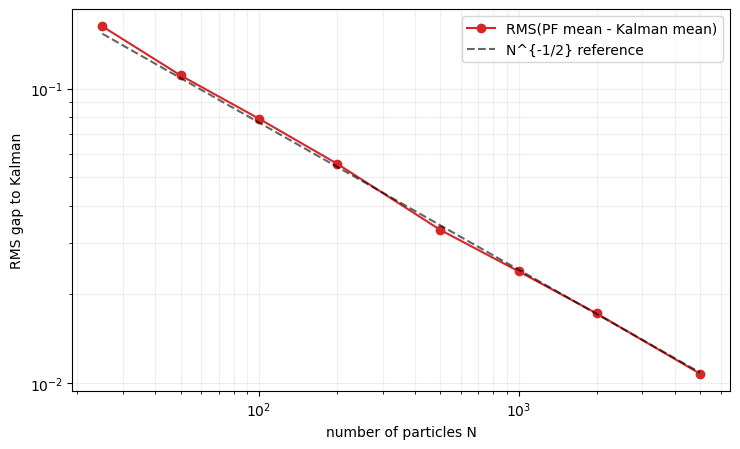

saved figures/ou_pf_convergence.pdf
PF-vs-Kalman RMS gap: {25: 0.1626, 50: 0.1108, 100: 0.0791, 200: 0.0556, 500: 0.0331, 1000: 0.024, 2000: 0.0172, 5000: 0.0108}


In [6]:
# PF mean converges to the Kalman mean as N grows. Measure their RMS gap vs N.
Ns = [25, 50, 100, 200, 500, 1000, 2000, 5000]
km_ref, _ = run_kalman(y0)         # exact posterior mean on the representative run
gaps = []
for N in Ns:
    reps = 100                     # average over more PF runs so each point is stable
    g = 0.0
    for r in range(reps):
        pm_N = run_pf(np.random.default_rng(BASE_SEED + 1000*r + N), y0, N)
        g += np.sqrt(np.mean((pm_N[1:] - km_ref[1:])**2))
    gaps.append(g/reps)
gaps = np.array(gaps)

# Reference line: slope fixed at -1/2, its height fitted on the asymptotic points
# (N >= 100), not anchored at the noisy small-N point. This way the guide tracks
# the clean tail and the data falls along it instead of drifting below it.
Ns_arr = np.array(Ns, dtype=float)
tail = Ns_arr >= 100
intercept = np.mean(np.log(gaps[tail]) + 0.5*np.log(Ns_arr[tail]))
ref = np.exp(intercept) / np.sqrt(Ns_arr)

plt.figure(figsize=(7.5, 4.6))
plt.loglog(Ns, gaps, "o-", color=COLORS["pf"], label="RMS(PF mean - Kalman mean)")
plt.loglog(Ns, ref, "k--", alpha=.6, label="N^{-1/2} reference")
plt.xlabel("number of particles N"); plt.ylabel("RMS gap to Kalman")
plt.legend(); plt.grid(alpha=.2, which="both")
savefig("ou_pf_convergence.pdf")
print("PF-vs-Kalman RMS gap:", dict(zip(Ns, np.round(gaps, 4))))

## Closing remarks

In the linear-Gaussian case the three filters agree: the Kalman filter is exact, the UKF reproduces it, and the particle filter converges to it as $N$ grows. This validates the three implementations against a known answer, before the nonlinear Kitagawa model, where no exact filter is available and the three methods diverge.